# OBJETIVO: Predecir el momento en el que la solicitud de triage de cualqueir tipo aunmentá, con la finalidad de determinar si es requerido mas personal en urgencias un momento determinado del tiempo 
1. Predecir puntos maximos de solicitudes de ingreso de Triage en un rango de tiempo (hora, dia de la seman, mes, año o temporda)
    NOTA: Principalmente en este punto se busca predecir el momento en el que las personas llegaran a solicitar el triage en el hospitla, para comenzar de poco a mucho, en este punto solo se buscará una prediccion inicial basado unicamente en las fechas de ingreso o creacion de los triags de la tabla principal y de ser necesario detablas que se relacionen con informacion apropiada

    1.1. Identificar y comprender las columnas y datos de la tabla principal.
        - Identificar significado de la columna y tipo de dato para determinar posibles columnas relacion
    
    1.2. Identificar y entender las relaciones de la tabla principal para entender el contexto
        - La base de datos no tiene llaves primarias y secundarias por lo cual la forma de identificar las relaciones entre tablas es deduciendo  conecciones entre columnas de cada tabla, la intencion de este item es poder identificar que columnas pueden ser conexiones con otra tabla y a su ves stas talbas como se relacionan con las demas para ramificar y relacionasr todas las tablas asociadas al area de urgencias con rspecto a los triages.
    
    1.3. Obtener informacion relacionada con las fechas historicas de atencion o ingreso de triage para entender horas, dias, semanas 
    y meses en los cuales ha existido un mayor incremento para entender el comportamiento de los datos en el tiempo.
        - se requiere de los datos histoicos de las fechas de ingreso de traige para comenzar con un analisis, normalizacion y limpieza del dato para poder saber con que se cuenta y como usarlo. 
    
    1.4. Encontrar y deducir el contexto del tiempo en la cual han sucedido estos incrementos
        - Se requiere generar un calendario natural para enender los dias del año en los que hay fechas especiales naturales de colombia como seria dias festivos o festividades.
        - Generar un claendario con las catastrofes, cambios climaticos, desastres natrales, pandemias, virus generales o tipicos de temporada que afectan a colombia
        - Realizar un calendaro historico mas encofado respecto a desasrtes enferedades y demas casos anomalos presentaos en la region caldense, eje cafetero y Manizales (donde está ubicado el hospital), para poder obtener mas contexto con el cual se pueda aforntar y entender las tendencias de los datos de la base de datos del hospital.
    
    1.5. Obtener conclusiones iniciales basado en la informacion y contexto obtenido de los anteriores puntos para obtener causas por las. cuales en ese tiempo amentó la cantidad de triages
    
    1.6. Usar las conclusiones obtenidas para generar documentacion y una base de datos inical de entrenamiento para el modelo predictivo
    
    1.7. Generar prediccion inicial
        
        * Usar un tiempo historico en el que haya sucedido un incremento en la cantidad de triages como punto de control para verificar que el el modelo logre predecir ese suceso 
        
2. Predecir ingreso de pacientes por triage
    NOTA: Se espera poder no solo determinar si va a haber un aumento n los tiages sino tambien cuantos de esos traiges serán verdaderamente ingreso de pacientes al hospital

3. Predecir retorno de pacientes
    NOTA: Predecir cuantos de esos pacients atendidos o ingresados tendran un retorno 

## Conexion con la base de datos via ODBC

In [9]:
import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

connection_url = URL.create(
    "mssql+pyodbc",
    host="ls-cobra",
    database="DWSES",
    query={
        "driver": "ODBC Driver 18 for SQL Server",
        "Trusted_Connection": "yes",
        "TrustServerCertificate": "yes",
    },
)

engine = create_engine(connection_url)

print("Conectado correctamente")

query = """
SELECT
    TABLE_SCHEMA,
    TABLE_NAME
FROM INFORMATION_SCHEMA.TABLES
WHERE TABLE_TYPE = 'BASE TABLE'
ORDER BY TABLE_SCHEMA, TABLE_NAME
"""

df_tablas = pd.read_sql(query, engine)

print(df_tablas.to_string(index=False))



Conectado correctamente
TABLE_SCHEMA                      TABLE_NAME
         dbo                  ACTIVIDADES_DW
         dbo                   ADNCIADMIN_DW
         dbo                       ALIMENTOS
         dbo           ANALISIS_RENTABILIDAD
         dbo                    ANTECEDENTES
         dbo                   AREA_SERVICIO
         dbo           AREA_SERVICIO_CIRUGIA
         dbo                AT_AMB_MAYO_2025
         dbo                ATC_DOMICILIARIA
         dbo               ATC_HOSPI_PARCIAL
         dbo                   BALANCE_DWSES
         dbo               BI_PROXIMAS_CITAS
         dbo                  camas_ocupadas
         dbo                   CENTRO_COSTOS
         dbo                    CHNCENARE_DW
         dbo                    CHNCENPRO_DW
         dbo                    CHNUNIFUN_DW
         dbo                  CIRUGIAS_DWSES
         dbo                   CITAS_MEDICAS
         dbo                       CMNTIPACT
         dbo       CONSOLIDADO_

c:\Users\ad6708\Documents\puebas\.venv311\Lib\site-packages\pandas\io\sql.py:1636: SAWarning: Unrecognized server version info '17.0.1000.7'.  Some SQL Server features may not function properly.
  con = self.exit_stack.enter_context(con.connect())


## Exploracion de la tabla principal y sus relaciones

*1.1.* Se identifico qu la tabla principal a la cual nos vamos a encfocar es la tabla DIM_TRIAGE de la cual vamos a extraer la informacion necesaria para la predicion, se debe de investigar tablas relacionadas a esta en pro del objetivo

In [10]:

query = """
SELECT
    COLUMN_NAME,
    DATA_TYPE
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_SCHEMA = 'dbo'
  AND TABLE_NAME = 'DIM_TRIAGE'
ORDER BY ORDINAL_POSITION
"""

df_triage_columnas = pd.read_sql(query, engine)

display(df_triage_columnas)


,COLUMN_NAME,DATA_TYPE
0,OID,int
1,HCTFECTRI,datetime
2,GPADOCUME,nvarchar
3,HCTEDAD,int
4,GENMEDICO,int
5,GPANOMBRE,nvarchar
6,GPASEGNOM,nvarchar
7,GPAAPELLI,nvarchar
8,GPASEGAPE,nvarchar
9,GEENENTADM,int


Se ha encontrado que las tablas *HCNCLAURGTR* (NIVEL DE URGENCIA) y *HCNCONTRDT* (Contiene detalles temporales, de estado y clave de turnos)

In [11]:
import pandas as pd

# Consulta para ver una muestra de los datos y validar la fecha/hora del triage
query_sample = """
SELECT TOP 10 
    OID,
    HCTFECTRI,
    HCTEDAD,
    HCNCLAURGTR,
    ADNINGRESO
FROM dbo.DIM_TRIAGE
ORDER BY HCTFECTRI DESC
"""

df_sample = pd.read_sql(query_sample, engine)
display(df_sample)

,OID,HCTFECTRI,HCTEDAD,HCNCLAURGTR,ADNINGRESO
0,844130,2026-09-03 07:57:25.737,67,10,NaN
1,844129,2026-09-03 07:18:47.227,25,19,2244124.0
2,844128,2026-09-03 07:16:33.180,26,16,2244126.0
3,844127,2026-09-03 06:59:26.973,41,9,NaN
4,844126,2026-09-03 06:50:04.730,22,19,2244102.0
5,844125,2026-09-03 05:57:50.003,25,19,2244084.0
6,844124,2026-09-03 05:32:39.387,22,10,NaN
7,844123,2026-09-03 04:51:56.083,55,16,NaN
8,844122,2026-09-03 04:40:53.137,68,16,2244082.0
9,844121,2026-09-03 04:26:02.787,54,9,NaN


In [12]:
import pandas as pd

# Consulta para listar las columnas de las tablas involucradas
query_columnas = """
SELECT 
    TABLE_NAME, 
    COLUMN_NAME, 
    DATA_TYPE 
FROM INFORMATION_SCHEMA.COLUMNS 
WHERE TABLE_SCHEMA = 'dbo' 
  AND TABLE_NAME IN ('DIM_TRIAGE', 'DIM_HCNCLAURGTR', 'DIM_HCNCONTRDT')
ORDER BY TABLE_NAME, ORDINAL_POSITION
"""

df_columnas = pd.read_sql(query_columnas, engine)
display(df_columnas)

,TABLE_NAME,COLUMN_NAME,DATA_TYPE
0,DIM_HCNCLAURGTR,OID,int
1,DIM_HCNCLAURGTR,HCCODIGO,nvarchar
2,DIM_HCNCLAURGTR,HCDESCRIP,nvarchar
3,DIM_HCNCONTRDT,OID,int
4,DIM_HCNCONTRDT,HCNCONCOTRI,int
5,DIM_HCNCONTRDT,HCCFECTUR,datetime
6,DIM_HCNCONTRDT,HCCFECSAL,datetime
7,DIM_HCNCONTRDT,HCCESTADO,int
8,DIM_HCNCONTRDT,HCLLTIPO,int
9,DIM_HCNCONTRDT,GENUSUARIO,int


Confirmamos que estas tres tablas estan relacionadas y generan datos importantes para le obejtivo de las cuales una de ellas etá relacionada con detalles del triage niveles y datos del paciente por lo cual se concluye que solo se tomará una de las tablas relacionadas:

| Tabla | Columna | Tipo (Ref.) | Descripción Funcional / Rol para el Análisis Temporal |
| --- | --- | --- | --- |
| **`DIM_TRIAGE`** | `OID` | int | Identificador único de cada registro de triage. Se usa para contar el volumen total de pacientes. |
|  | `HCTFECTRI` | datetime | **Fecha y hora exacta del triage.** Es la variable más importante para extraer horas, días y temporadas. |
|  | `GPADOCUME` | nvarchar | Documento de identidad del paciente (útil si se requiere validar unicidad de personas). |
|  | `HCTEDAD` | int | Edad del paciente. |
|  | `GENMEDICO` | int | Identificador del médico o personal que realiza el proceso. |
|  | `GPANOMBRE` | nvarchar | Primer nombre del paciente. |
|  | `GPASEGNOM` | nvarchar | Segundo nombre del paciente. |
|  | `GPAAPELLI` | nvarchar | Primer apellido del paciente. |
|  | `GPASEGAPE` | nvarchar | Segundo apellido del paciente. |
|  | `GEENENTADM` | int | Entidad administradora o aseguradora relacionada. |
|  | `HCNCLAURGTR` | int | Llave hacia la clasificación de urgencia (se conserva por si se quiere filtrar por severidad más adelante). |
|  | `HCNCONTRDT` | int | **Llave de relación** con la tabla de control de turnos (`DIM_HCNCONTRDT`). |
|  | `GENDIAGNO1` | int | Código del diagnóstico principal de ingreso. |
|  | `ADNINGRESO` | int | Identificador del ingreso hospitalario asociado. |
| **`DIM_HCNCONTRDT`** | `OID` | int | Identificador único del registro de control/turno. Se usa para hacer el `JOIN` con `DIM_TRIAGE`. |
|  | `HCNCONCOTRI` | int | Referencia al control o tipo de gestión de triage. |
|  | `HCCFECTUR` | datetime | **Fecha y hora del turno asignado.** Permite contrastar el momento de la cita/turno frente a la hora del triage. |
|  | `HCCFECSAL` | datetime | Fecha y hora de salida o finalización del control. |
|  | `HCCESTADO` | int | Estado actual del contrato o turno (ej. activo, finalizado). |
|  | `HCLLTIPO` | int | Tipo de llamada o modalidad de atención del turno. |
|  | `GENUSUARIO` | int | Usuario del sistema que generó o gestionó el turno. |
|  | `HCCTTURNO` | int | **Número consecutivo del turno.** Permite analizar la saturación o el flujo secuencial de pacientes. |

---


| Tabla | Rol Analítico Actualizado | Columnas Críticas |
| --- | --- | --- |
| **`DIM_TRIAGE`** | **Núcleo de eventos.** Registra cada llegada y el momento exacto en que se realiza el proceso de triage. | `OID`, `HCTFECTRI` (Hora de llegada/triage), `HCNCLAURGTR`, `HCNCONTRDT` (Llave hacia los turnos). |
| **`DIM_HCNCONTRDT`** | **Control de Turnos y Tiempos.** Contiene el número del turno asignado y las marcas de tiempo del proceso de atención. | `OID`, `HCCTTURNO` (Número de turno), `HCCFECTUR` (Fecha del turno), `HCCESTADO`. |

In [13]:
import pandas as pd

# Consulta para cruzar DIM_TRIAGE con sus dimensiones correspondientes
query_match_exacto = """
SELECT TOP 5
    -- Datos de DIM_TRIAGE
    t.OID AS Triage_OID,
    t.HCTFECTRI AS Fecha_Hora_Triage,
    t.HCTEDAD AS Edad_Paciente,
    t.GPADOCUME AS Documento,
    
    -- Datos de Control/Turnos (DIM_HCNCONTRDT)
    dt.HCNCONCOTRI AS Control_Triage_ID,
    dt.HCCFECTUR AS Fecha_Turno,
    dt.HCCTTURNO AS Numero_Turno,
    dt.HCCESTADO AS Estado_Contrato
    
FROM dbo.DIM_TRIAGE t
LEFT JOIN dbo.DIM_HCNCONTRDT dt ON t.HCNCONTRDT = dt.OID
WHERE t.HCTFECTRI IS NOT NULL
ORDER BY t.HCTFECTRI DESC
"""

df_resultado_match = pd.read_sql(query_match_exacto, engine)
display(df_resultado_match)

,Triage_OID,Fecha_Hora_Triage,Edad_Paciente,Documento,Control_Triage_ID,Fecha_Turno,Numero_Turno,Estado_Contrato
0,844130,2026-09-03 07:57:25.737,67,24823144,4.0,2026-09-03 07:52:19.247,4.0,1.0
1,844129,2026-09-03 07:18:47.227,25,1002547200,5.0,2026-09-03 07:15:19.210,4.0,1.0
2,844128,2026-09-03 07:16:33.180,26,1002547652,NaN,NaT,NaN,NaN
3,844127,2026-09-03 06:59:26.973,41,9977626,1.0,2026-09-03 06:52:31.763,5.0,1.0
4,844126,2026-09-03 06:50:04.730,22,1053766501,5.0,2026-09-03 06:43:45.190,3.0,1.0


Solo se toman en cuenta estas dos tablas y columnas debido a que las demas relacion que respectan a estas tablas son detalles del triage y porcesos relaizdos, lo cual se expande al objetivo inicia l, por lo cual se decide solo tomar estas dos talbas con sus respectivas columnas de fecha para poder entender y obtenerdatos historicos crecimiento.

Con esta informaicon procedemos a explorar las talbas para continuar con el proceso de ETL, revisando pricipalmente con que datos contamos y si hay duplicados y y nullos que limpiar

In [14]:
import pandas as pd

# 1. Consulta SQL para traer las columnas relevantes de ambas tablas con su respectivo match
query_analisis = """
SELECT 
    t.OID AS Triage_OID,
    t.HCTFECTRI,
    t.HCTEDAD,
    t.GPADOCUME,
    t.HCNCLAURGTR,
    t.ADNINGRESO,
    dt.OID AS Turno_OID,
    dt.HCCFECTUR,
    dt.HCCFECSAL,
    dt.HCCESTADO,
    dt.HCCTTURNO
FROM dbo.DIM_TRIAGE t
LEFT JOIN dbo.DIM_HCNCONTRDT dt ON t.HCNCONTRDT = dt.OID
WHERE t.HCTFECTRI IS NOT NULL
"""

# Cargar los datos a un DataFrame
df_triage_turnos = pd.read_sql(query_analisis, engine)

print(f"Dimensiones iniciales del dataset (Filas, Columnas): {df_triage_turnos.shape}")
print("-" * 50)

# 2. Revisión de Valores Nulos (Missing Values)
print("--- REVISIÓN DE VALORES NULOS ---")
nulos = df_triage_turnos.isnull().sum()
porcentaje_nulos = (df_triage_turnos.isnull().mean()) * 100
df_nulos = pd.DataFrame({'Valores Nulos': nulos, 'Porcentaje (%)': porcentaje_nulos})
display(df_nulos[df_nulos['Valores Nulos'] > 0])
print("-" * 50)

# 3. Revisión de Registros Duplicados
# Evaluamos duplicados por documento del paciente y la fecha exacta del triage
duplicados_doc_fecha = df_triage_turnos.duplicated(subset=['GPADOCUME', 'HCTFECTRI']).sum()
print(f"Duplicados exactos basados en Documento y Fecha/Hora de Triage: {duplicados_doc_fecha}")

duplicados_totales = df_triage_turnos.duplicated().sum()
print(f"Filas totalmente duplicadas en el DataFrame: {duplicados_totales}")
print("-" * 50)

# 4. Mostrar una muestra de filas para inspeccionar los datos visualmente
print("--- MUESTRA DE DATOS (Primeras 10 filas) ---")
display(df_triage_turnos.head(10))

Dimensiones iniciales del dataset (Filas, Columnas): (430137, 11)
--------------------------------------------------
--- REVISIÓN DE VALORES NULOS ---


,Valores Nulos,Porcentaje (%)
ADNINGRESO,253604,58.958890
Turno_OID,38239,8.889958
HCCFECTUR,38239,8.889958
HCCFECSAL,38313,8.907162
HCCESTADO,38239,8.889958
HCCTTURNO,289240,67.243692


--------------------------------------------------
Duplicados exactos basados en Documento y Fecha/Hora de Triage: 0
Filas totalmente duplicadas en el DataFrame: 0
--------------------------------------------------
--- MUESTRA DE DATOS (Primeras 10 filas) ---


,Triage_OID,HCTFECTRI,HCTEDAD,GPADOCUME,HCNCLAURGTR,ADNINGRESO,Turno_OID,HCCFECTUR,HCCFECSAL,HCCESTADO,HCCTTURNO
0,388518,2020-01-01 00:26:36.313,16,1002592990,19,1162936.0,100039.0,2020-01-01 00:17:41.853,2020-01-01 00:24:43.377,1.0,NaN
1,388519,2020-01-01 00:31:44.597,40,75093115,10,NaN,100040.0,2020-01-01 00:18:18.480,2020-01-01 00:27:17.090,1.0,NaN
2,388520,2020-01-01 00:40:01.923,36,16074420,10,NaN,100041.0,2020-01-01 00:30:41.563,2020-01-01 00:32:19.813,1.0,NaN
3,388521,2020-01-01 00:45:06.337,30,1053793557,2,1162937.0,100042.0,2020-01-01 00:39:57.680,2020-01-01 00:42:17.017,1.0,NaN
4,388522,2020-01-01 01:11:53.167,74,24290752,16,1162938.0,100043.0,2020-01-01 01:01:43.407,2020-01-01 01:02:59.103,1.0,NaN
5,388523,2020-01-01 01:47:23.697,60,24866969,16,1162939.0,100044.0,2020-01-01 01:40:56.807,2020-01-01 01:44:24.003,1.0,NaN
6,388524,2020-01-01 02:28:37.640,50,28742060,16,1162941.0,100045.0,2020-01-01 02:12:15.440,2020-01-01 02:15:34.363,1.0,NaN
7,388525,2020-01-01 02:34:01.333,61,24328674,10,NaN,100046.0,2020-01-01 02:21:07.973,2020-01-01 02:29:51.947,1.0,NaN
8,388526,2020-01-01 02:37:29.860,61,10261965,16,1162942.0,100047.0,2020-01-01 02:33:38.327,2020-01-01 02:35:36.120,1.0,NaN
9,388527,2020-01-01 02:57:56.280,72,10223485,16,1162943.0,100048.0,2020-01-01 02:52:43.127,2020-01-01 02:56:01.447,1.0,NaN


Se concluye que los datos son bastante positivos a lo esperado: no existen datos duplicados y a pesar de que hay datos nulos, son esperados debido a contexto de las columnas, un usuario no siempre es ingresado al hospital debido a que no tiene un nivel de triage adecuado para ser ingresado al no suceder esto no existe ingreso por lo cual es null, y parce que el numero de turno fue una agregacion puesta a mediados de 2024 por lo cual se entiende que existan estos datos nulos, teniendo en cuenta que el numeor o cogo del turno no afecta perjudicialmente a la calidad de la prediccion propuesta.

Se procede con la revision del comportamiento de atencion de triage basado en los historicos para revisar la tendencia de mayor y menor congestion del servicio a lo largo del dia, meses y años.

In [15]:
import calplot
import matplotlib.pyplot as plt
import pandas as pd

fecha = pd.to_datetime(df_triage_turnos["HCTFECTRI"])

# Serie diaria completa. Días sin registro quedan en NaN (gris), no en cero.
serie = fecha.dt.normalize().value_counts().sort_index()
serie = serie.reindex(pd.date_range(serie.index.min(), serie.index.max(), freq="D"))

ETIQUETAS_ANIO = {"fontname": "DejaVu Sans", "fontsize": 26, "color": "#9a9a9a"}

# ---------------------------------------------------------
# FIGURA 1: día a día
# ---------------------------------------------------------
calplot.calplot(
    serie,
    how=None,
    cmap="YlOrRd",
    fillcolor="#eeeeee",
    linewidth=0.5,
    figsize=(16, 2.0 * serie.index.year.nunique()),
    suptitle="Atenciones diarias de triage",
    yearlabel_kws=ETIQUETAS_ANIO,
    colorbar=True,
)
plt.show()

# ---------------------------------------------------------
# FIGURA 2: año, mes y semana
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9),
                               gridspec_kw={"height_ratios": [1.1, 1]})

# Panel superior: promedio diario por mes y año (evita el sesgo de meses
# de distinta duración y de años incompletos)
matriz = (serie.groupby([serie.index.year, serie.index.month]).mean()
          .unstack().reindex(columns=range(1, 13)))
matriz.columns = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                  "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

im = ax1.imshow(matriz.values, cmap="YlOrRd", aspect="auto")
ax1.set_xticks(range(12), matriz.columns)
ax1.set_yticks(range(len(matriz)), matriz.index)
ax1.set_title("Promedio de atenciones por día, según mes y año", weight="bold")
fig.colorbar(im, ax=ax1, label="atenciones/día")

for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.values[i, j]
        if pd.notna(v):
            ax1.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8)

# Panel inferior: serie semanal continua
semanal = serie.resample("W").mean()
ax2.plot(semanal.index, semanal.values, linewidth=1.2, color="#c0392b")
ax2.plot(semanal.index, semanal.rolling(8, min_periods=1).mean(),
         linewidth=2.2, color="#2c3e50", label="media móvil 8 semanas")
ax2.set_title("Promedio diario por semana", weight="bold")
ax2.set_ylabel("atenciones/día")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'calplot'

Basado en la evidencia obtenida podemos encontrar patrones y tendencias historicas como un aumneto progresivo en la los triages ralizado a lo largo de los años, sienod cada vez mayor la cantidad que se genera en le hospital, a su ves, se encuentran tendencias a puntos criticos de atencion en mitades del año aumentando progresivamnete desde enero y llegando al punto mas alto en junio y julio donde se genera una corta caida progresiva hasta diciembre generando un efecto de campana de gaus. Adicional a esto se puede identificar como en a pesar de tener alguno patrones marcados en los años, algos tiene mas o menos cantidad de atenciones en difente mes o en u año se pueden generar mas atenciones teniendo patrones dificiles de determinar solo con la cantidad de registros de triage. 

Por lo cual se concluye que es necesario obtener mas contexto fuera de la base de datos para entender la causa de estos aumentos repentinos fuera de los patrones de tendencia normales para asi determinar que factores externos pueden influir en la cantidad de triages realizados en cierto tiempo. Para esto, se realizará un calendario de eventos hisotiricos relacionados con manizales y sus alrededores, efectos climaticos o temporadas de enfermedades y calendario normal de colombia para determinar si estos factes inlfuyen de alguna manera a las tendencias de crecimienot o disminucion de las solicitudes de triage. 

### Se crean 5 archivos calendario para generar un mayor contexto a las tendecias encontradas.

Se encontró que solo existen datos histoicos desde el 2020 hasta la fecha actual 20206 en la base de datos DWSES, por lo cual los historicos calendarios se toman en ese mismo rango de fechas.

1. calendarios\calendario_Colombia.csv -> Calendario natural de colombia donde se puede encontrar dias festivos, y festividades culturales Colombianas.

2. calendarios\clima_unificado.csv -> Datos hisotoricos climaticos de manizales de 5 difernetes fuentes y son unificados en este archivo.
    - Usando las 5 fuentes de informacion se tomaorn las diferntes datos climaticos para generar mediana que pueda aportar un rango mas real aproxmado de la realidad de cada uno de los dias segun las difernete sfuestes de unformacion.
    - se agregaron las columnas de todos los archvos para generar una base de datos mas completa de toda la informaicon climatica disponible.

3. calendarios\desastres_manizales_2020_2026.csv -> Se investigaron los eventos  historicos catastroficos que se han producido en manizales como pueden ser deslizamientos, sismos, inincaciones o vendabales.

4. calendarios\eventos_manizales_2020_2026.csv -> Base de datos de eventos grandes propducidos en manizales teniendo en cuenta eventos internacionales, culturales y fiestas.

5. calendarios\vigilancia_salud_manizales_caldas.csv -> Investigaciony documentacion historica de sucesos relacionados con la salud en mainzales tales como pandemias, epidemias, temporadas de enfermedades o virus, entre otors.
  
Ahora inyectan estos datos historicos en el df para poder ser usados con la base de datos comparandolos con los hstoricos de las tendencias de triage.

In [ ]:
import pandas as pd
from IPython.display import display

# Cargar archivos

df_calendario = pd.read_csv(
    r"calendarios\calendario_Colombia.csv"
)

df_clima = pd.read_csv(
    r"calendarios\clima_unificado.csv"
)

df_desastres = pd.read_csv(
    r"calendarios\desastres_manizales_2020_2026.csv"
)

df_eventos = pd.read_csv(
    r"calendarios\eventos_manizales_2020_2026.csv"
)

df_salud = pd.read_csv(
    r"calendarios\vigilancia_salud_manizales_caldas.csv"
)


print("✅ Se creó el dataframe CALENDARIO_COLOMBIA")
display(df_calendario.head(1))

print("✅ Se creó el dataframe CLIMA")
display(df_clima.head(1))

print("✅ Se creó el dataframe DESASTRES")
display(df_desastres.head(1))

print("✅ Se creó el dataframe EVENTOS")
display(df_eventos.head(1))

print("✅ Se creó el dataframe SALUD")
display(df_salud.head(1))

✅ Se creó el dataframe CALENDARIO_COLOMBIA


,fecha,anio,mes,nombre_mes,dia,dia_semana,nombre_dia,dia_anio,semana_iso,trimestre,...,es_semana_santa,es_domingo_ramos,es_jueves_santo,es_viernes_santo,es_domingo_resurreccion,es_novena,es_temporada_fin_anio,es_quincena,es_vacaciones_escolares,evento_calendario
0,2020-01-01,2020,1,Enero,1,2,Miércoles,1,1,1,...,0,NaN,NaN,NaN,NaN,0,1,0,1,Año Nuevo


✅ Se creó el dataframe CLIMA


,fecha,precipitacion_mm,completitud_precip,temp_media,temp_min,temp_max,n_registros_temp,estacion_clima,estacion_km,om_temperature_2m_mean,...,radiacion_consenso,n_fuentes_temp,llovio,lluvia_fuerte,dia_calido,dia_frio,precip_7d,precip_30d,temp_media_7d,humedad_7d
0,2020-01-01,11.1,1.0,14.66,12.8,18.2,24.0,TESORITO FINCA,7.7,16.6,...,15.3,3,1,0,0,0,11.1,11.1,16.61,90.62


✅ Se creó el dataframe DESASTRES


,fecha_inicio,fecha_fin,anio,tipo_evento,subtipo,municipio,sector_o_barrio,descripcion,muertos,heridos,...,familias_damnificadas,viviendas_afectadas,personas_evacuadas,nivel_alerta,declaratoria,impacto_hospitalario,impacto_vial,ambito,calidad_dato,fuente_url
0,2020-11-01,2020-12-31,2020,deslizamiento,movimientos_en_masa_temporada,Manizales,varios,Segunda temporada de lluvias 2020 intensificad...,NaN,NaN,...,NaN,NaN,NaN,por_verificar,NaN,NaN,NaN,municipal,pendiente_verificacion,https://centrodeinformacion.manizales.gov.co/


✅ Se creó el dataframe EVENTOS


,nombre_evento,edicion,anio,fecha_inicio,fecha_fin,duracion_dias,categoria,municipio,lugar,descripcion,estado,calidad_fecha,asistencia_impacto,fuente_url
0,Feria de Manizales,64.0,2020,2020-01-04,2020-01-12,9.0,feria,Manizales,Ciudad,Edicion 64 de la Feria de Manizales,realizado,confirmada,NaN,https://www.eltiempo.com


✅ Se creó el dataframe SALUD


,nombre_evento,categoria,subcategoria,patogeno_o_agente,anio,fecha_inicio,fecha_fin,duracion_dias,ambito_territorial,lugar_o_institucion,descripcion,casos,muertes,tasa_o_indicador,estado,calidad_fecha,fuente_url
0,Dengue Caldas 2024 (a semana 30),vectores,dengue,Virus dengue (DENV),2024,2024-01-01,2024-07-27,208,caldas,Direccion Territorial de Salud de Caldas,Casos probables y confirmados a SE30; Salamina...,1744.0,NaN,NaN,confirmado,estimada,https://saluddecaldas.gov.co/publicaciones/453...


Ahora que se tiene una mayor base de datos y contexto de eventos historios relacionados a manizales, se puede tomar en cuenta el df de triage para ser comparado con las fechas de cada uno de los df de contexto generado para poder relaiconar patrones de tendencia de aumentos desde las 5 diferenetes perspectivas, con la intencion de identificar patrones de incrementos de triage con algunasituacion externa al entorno hospitalario.

Comenzando con una comparativa entre el triage y el calendario colombiano.

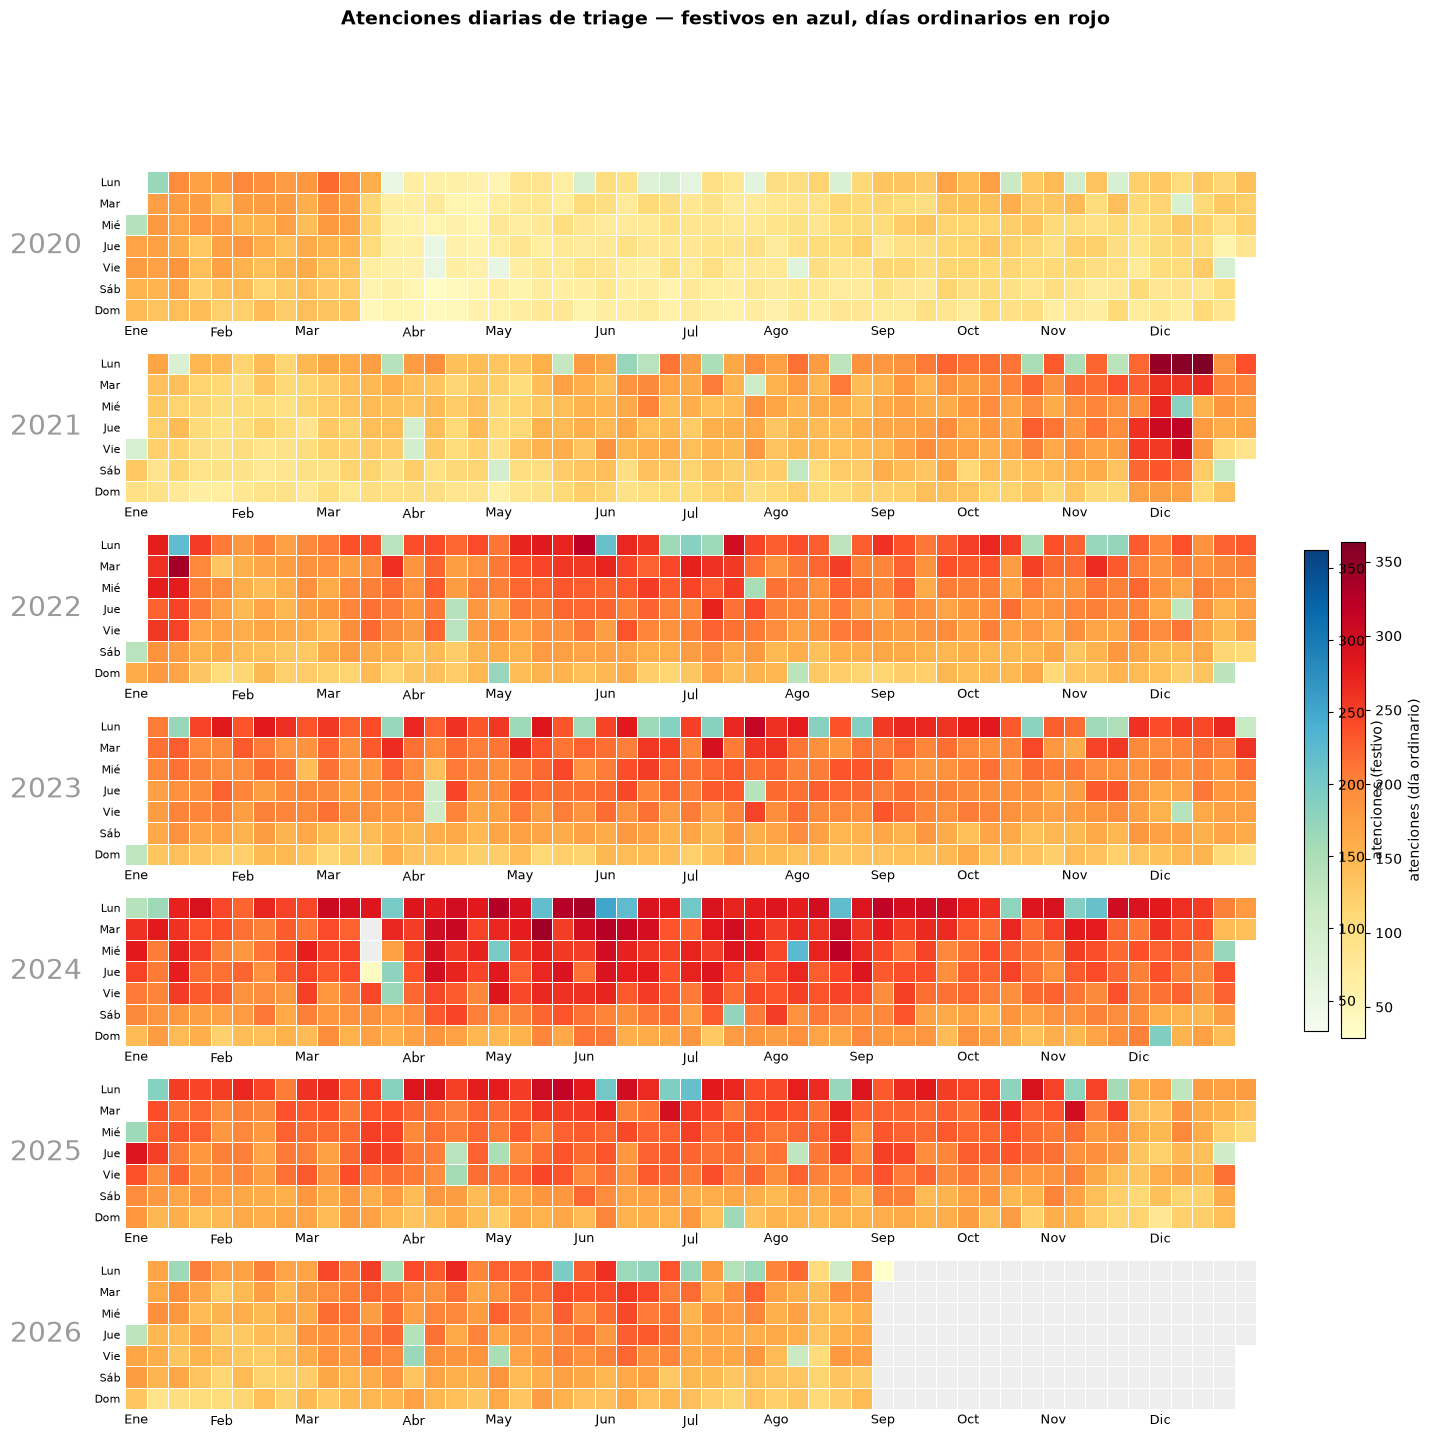

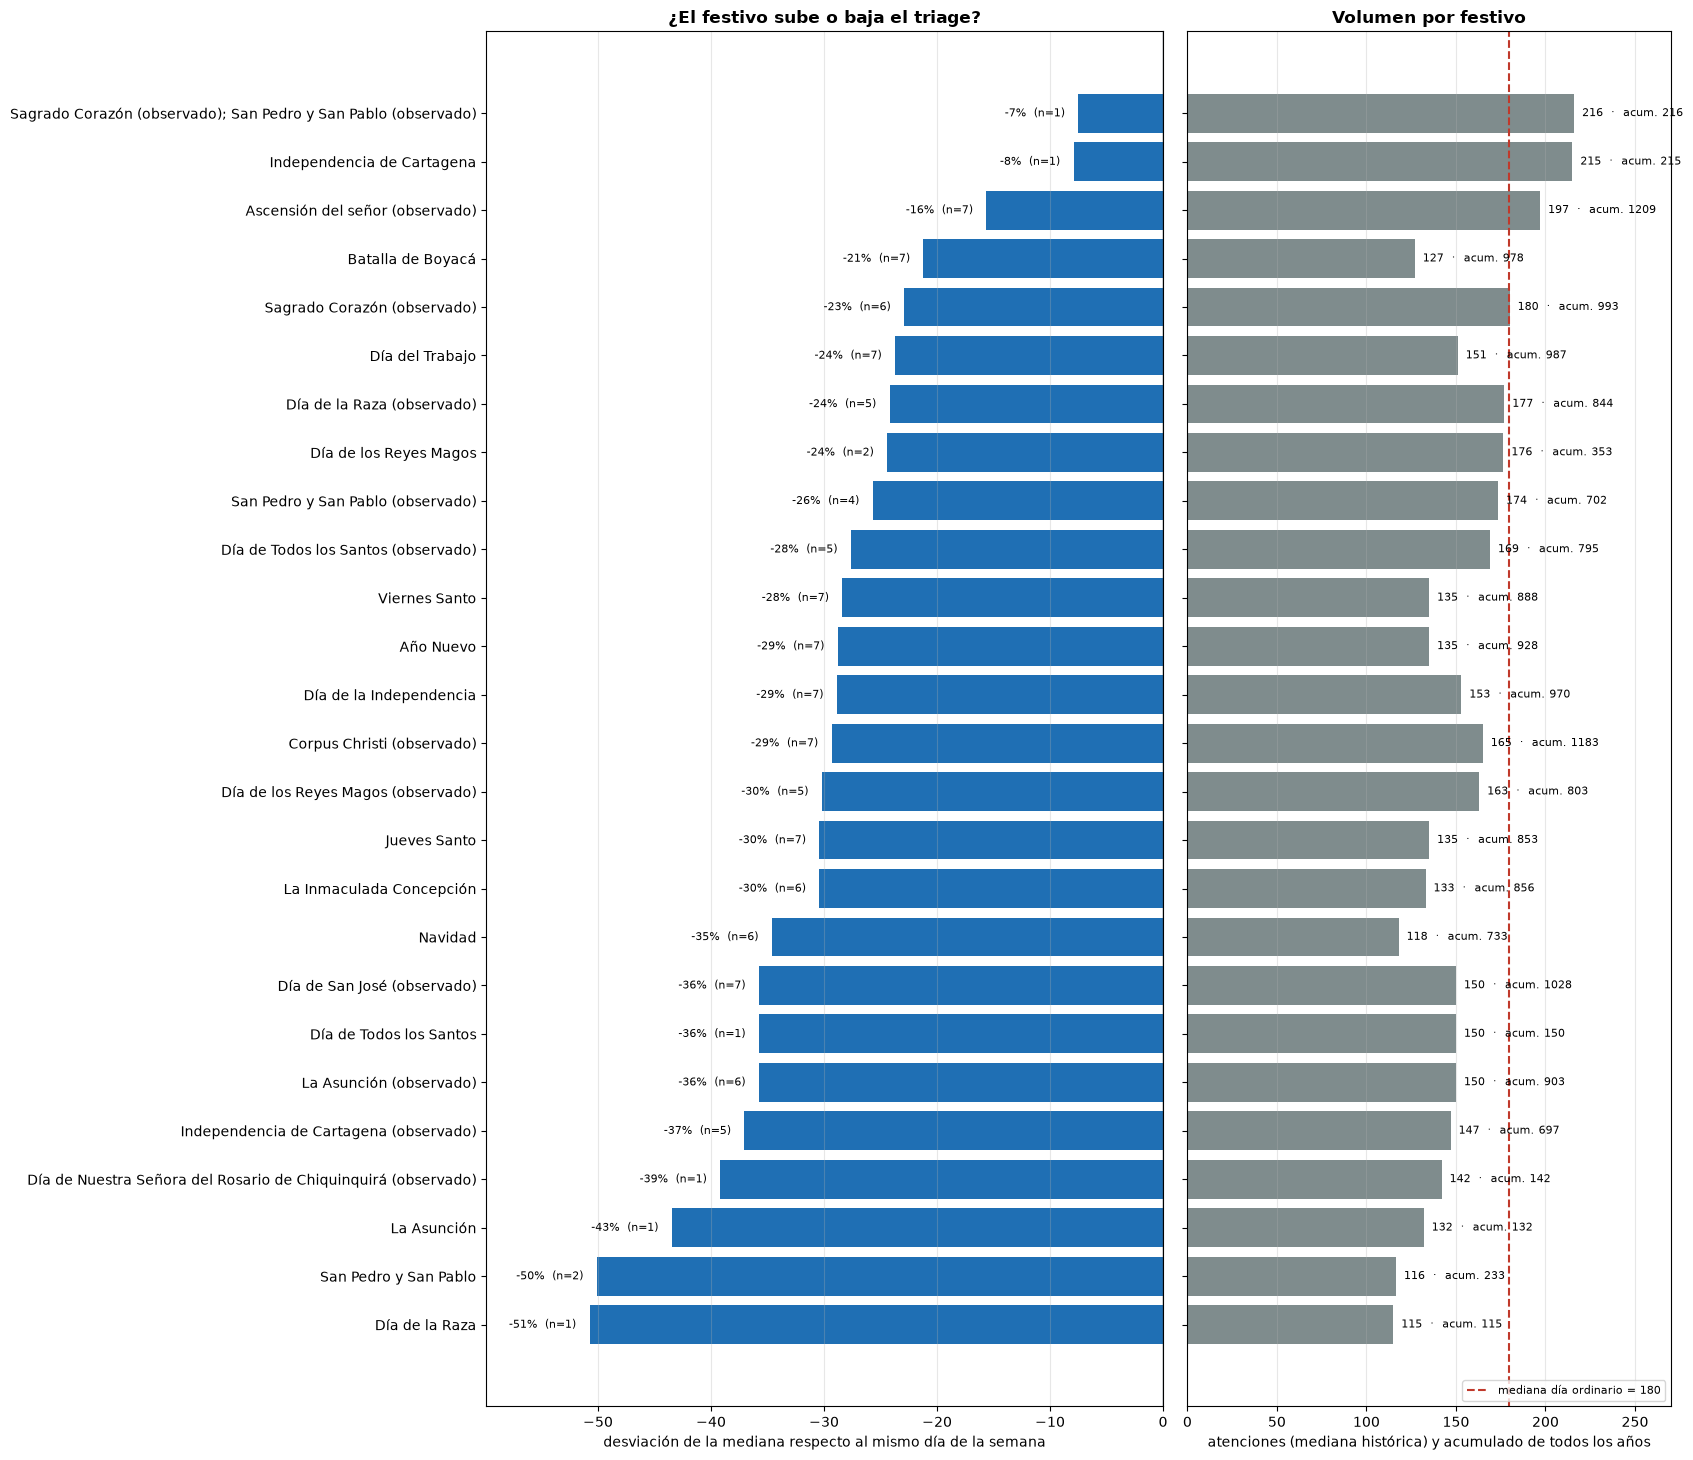

                                                    mediana   desv_pct  \
nombre                                                                   
Sagrado Corazón (observado); San Pedro y San Pa...    216.0  -7.494647   
Independencia de Cartagena                            215.0  -7.922912   
Ascensión del señor (observado)                       197.0 -15.631692   
Batalla de Boyacá                                     127.0 -21.199143   
Sagrado Corazón (observado)                           180.0 -22.912206   
Día del Trabajo                                       151.0 -23.711340   
Día de la Raza (observado)                            177.0 -24.197002   
Día de los Reyes Magos                                176.5 -24.411135   
San Pedro y San Pablo (observado)                     173.5 -25.695931   
Día de Todos los Santos (observado)                   169.0 -27.623126   
Viernes Santo                                         135.0 -28.381963   
Año Nuevo                             

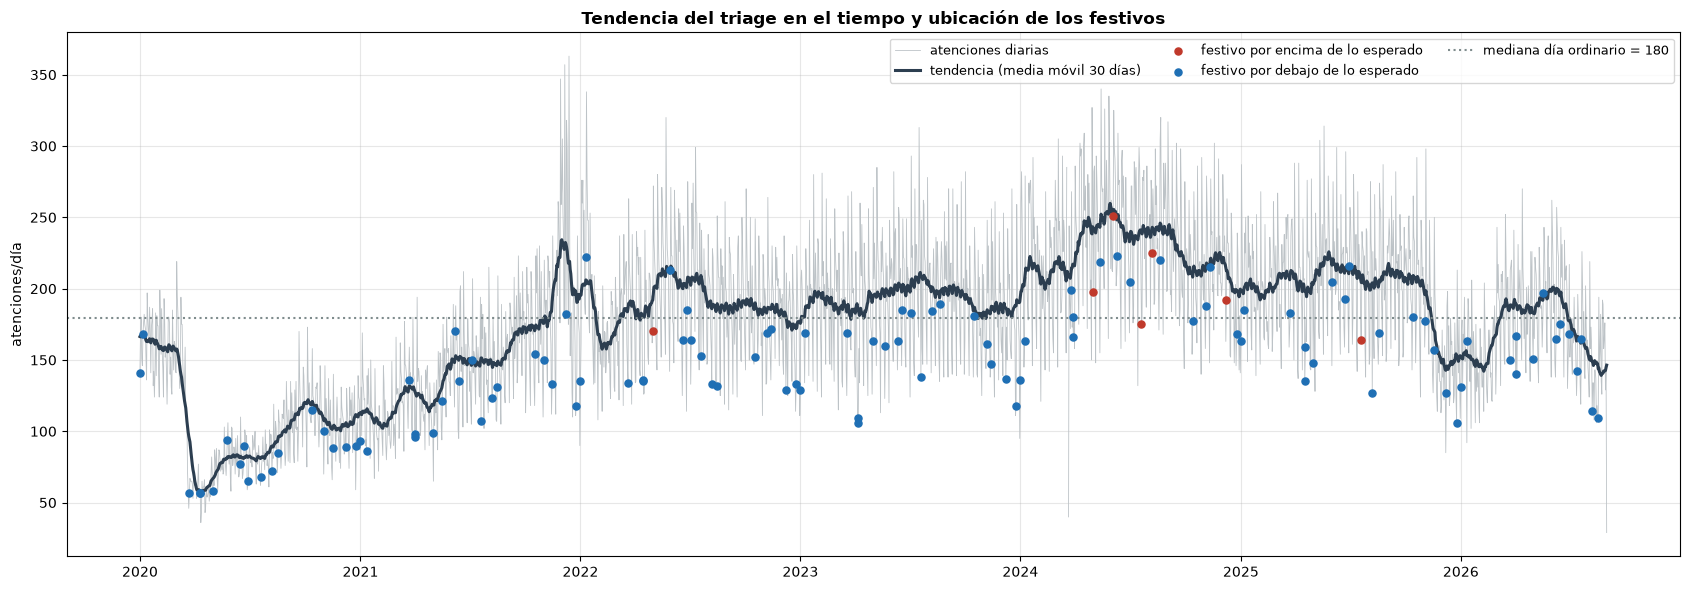

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, ListedColormap
from matplotlib.cm import ScalarMappable

# ---------------- datos base ----------------
fecha = pd.to_datetime(df_triage_turnos["HCTFECTRI"], errors="coerce")
serie = fecha.dt.normalize().value_counts().sort_index()
serie = serie.reindex(pd.date_range(serie.index.min(), serie.index.max(), freq="D"))

cal = df_calendario.copy()
cal["fecha"] = pd.to_datetime(cal["fecha"], errors="coerce")
cal = cal.dropna(subset=["fecha"]).set_index("fecha")
cal = cal.reindex(serie.index)

fest = cal.get("es_festivo", pd.Series(False, index=cal.index))
fest = fest.fillna(False).astype(bool)

nombre = cal.get("evento_calendario", pd.Series("", index=cal.index))
nombre = nombre.fillna("")

CMAP_NORMAL, CMAP_FEST = "YlOrRd", "GnBu"
vals = serie.to_numpy(dtype=float)
vals_valid = vals[~pd.isna(vals)]
norm = Normalize(vals_valid.min(), vals_valid.max()) if len(vals_valid) > 0 else Normalize(0, 1)
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

# ---------------- FIGURA 1: calendario superpuesto ----------------
anios = sorted(serie.index.year.unique())
fig, axes = plt.subplots(len(anios), 1, figsize=(16, 2.3 * len(anios)), squeeze=False)

for ax, anio in zip(axes[:, 0], anios):
    idx = pd.date_range(f"{anio}-01-01", f"{anio}-12-31", freq="D")
    val = serie.reindex(idx).to_numpy(dtype=float)
    esf = fest.reindex(idx).fillna(False).to_numpy(dtype=bool)

    offset = pd.Timestamp(f"{anio}-01-01").dayofweek
    semana = ((idx.dayofyear.to_numpy() - 1 + offset) // 7).astype(int)
    dia = idx.dayofweek.to_numpy(dtype=int)
    nsem = int(semana.max()) + 1

    fondo = np.full((7, nsem), np.nan, dtype=float)
    base = np.full((7, nsem), np.nan, dtype=float)
    ev = np.full((7, nsem), np.nan, dtype=float)

    fondo[dia, semana] = 1.0
    mask = ~pd.isna(val)
    if np.any(mask):
        fila = dia[mask & ~esf]
        col = semana[mask & ~esf]
        base[fila, col] = val[mask & ~esf]

        fila_fest = dia[mask & esf]
        col_fest = semana[mask & esf]
        ev[fila_fest, col_fest] = val[mask & esf]

    kw = dict(edgecolors="white", linewidth=0.5)
    ax.pcolormesh(np.ma.masked_invalid(fondo), cmap=ListedColormap(["#eeeeee"]), **kw)
    ax.pcolormesh(np.ma.masked_invalid(base), cmap=CMAP_NORMAL, norm=norm, **kw)
    ax.pcolormesh(np.ma.masked_invalid(ev), cmap=CMAP_FEST, norm=norm, **kw)

    meses_en_anio = [m for m in range(1, 13) if np.any(idx.month == m)]
    pos_mes = []
    labels = []
    for mth in meses_en_anio:
        pos = np.where(idx.month == mth)[0]
        if len(pos) > 0:
            pos_mes.append(semana[pos[0]] + 0.5)
            labels.append(MESES[mth - 1])
    ax.set_xticks(pos_mes, labels, fontsize=9)
    ax.set_yticks(np.arange(7) + 0.5, DIAS, fontsize=8)
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.set_frame_on(False)
    ax.tick_params(length=0)
    ax.set_ylabel(anio, fontsize=20, color="#9a9a9a", rotation=0, labelpad=35, va="center")

fig.suptitle("Atenciones diarias de triage — festivos en azul, días ordinarios en rojo",
             fontsize=14, weight="bold")
fig.colorbar(ScalarMappable(norm=norm, cmap=CMAP_NORMAL), ax=axes[:, 0].tolist(),
             fraction=0.02, pad=0.01, label="atenciones (día ordinario)")
fig.colorbar(ScalarMappable(norm=norm, cmap=CMAP_FEST), ax=axes[:, 0].tolist(),
             fraction=0.02, pad=0.04, label="atenciones (festivo)")
plt.show()

# ---------------- FIGURA 2: volumen por festivo vs. comportamiento normal ----------------
base_dia = pd.DataFrame({
    "conteo": serie.to_numpy(dtype=float),
    "dow": serie.index.dayofweek,
    "festivo": fest.reindex(serie.index).fillna(False).to_numpy(dtype=bool),
    "nombre": nombre.reindex(serie.index).fillna("").to_numpy(dtype=object)
}, index=serie.index).dropna(subset=["conteo"])

mediana_global = base_dia.loc[~base_dia["festivo"], "conteo"].median()
mediana_dow = base_dia.loc[~base_dia["festivo"]].groupby("dow")["conteo"].median()

fdias = base_dia[base_dia["festivo"] & base_dia["nombre"].ne("")].copy()
if not fdias.empty:
    fdias["esperado_dow"] = fdias["dow"].map(mediana_dow)
    fdias["desv_pct"] = 100 * (fdias["conteo"] - fdias["esperado_dow"]) / fdias["esperado_dow"]
    res = (
        fdias.groupby("nombre")
        .agg(mediana=("conteo", "median"), desv_pct=("desv_pct", "median"), n_anios=("conteo", "size"), total=("conteo", "sum"))
        .sort_values("desv_pct")
    )
else:
    res = pd.DataFrame(columns=["mediana", "desv_pct", "n_anios", "total"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 0.45 * len(res) + 3) if not res.empty else (17, 3),
                               gridspec_kw={"width_ratios": [1.4, 1]}, sharey=True)

if not res.empty:
    colores = np.where(res["desv_pct"] >= 0, "#c0392b", "#1f6fb4")
    ax1.barh(res.index, res["desv_pct"], color=colores)
    ax1.axvline(0, color="#2c3e50", linewidth=1)
    for y, (v, n) in enumerate(zip(res["desv_pct"], res["n_anios"])):
        ax1.text(v + (1.2 if v >= 0 else -1.2), y, f"{v:+.0f}%  (n={n})",
                 va="center", ha="left" if v >= 0 else "right", fontsize=8)
    ax1.set_xlabel("desviación de la mediana respecto al mismo día de la semana")
    ax1.set_title("¿El festivo sube o baja el triage?", weight="bold")
    ax1.grid(axis="x", alpha=0.3)
    ax1.margins(x=0.18)

    ax2.barh(res.index, res["mediana"], color="#7f8c8d")
    ax2.axvline(mediana_global, color="#c0392b", linestyle="--",
                label=f"mediana día ordinario = {mediana_global:.0f}")
    for y, (m, t) in enumerate(zip(res["mediana"], res["total"])):
        ax2.text(m, y, f"  {m:.0f}  ·  acum. {t:.0f}", va="center", fontsize=8)
    ax2.set_xlabel("atenciones (mediana histórica) y acumulado de todos los años")
    ax2.set_title("Volumen por festivo", weight="bold")
    ax2.legend(loc="lower right", fontsize=8)
    ax2.grid(axis="x", alpha=0.3)
    ax2.margins(x=0.25)
else:
    ax1.text(0.5, 0.5, "Sin datos de festivos con nombre disponible", ha="center", va="center")
    ax1.set_axis_off()
    ax2.set_axis_off()

plt.tight_layout()
plt.show()

if not res.empty:
    print(res.sort_values("desv_pct", ascending=False))

# ---------------- FIGURA 3: tendencia temporal con festivos marcados ----------------
fig, ax = plt.subplots(figsize=(17, 6))
ax.plot(serie.index, serie.values, linewidth=0.6, color="#bdc3c7", label="atenciones diarias")
ax.plot(serie.index, serie.rolling(30, min_periods=7, center=True).mean(),
        linewidth=2.2, color="#2c3e50", label="tendencia (media móvil 30 días)")

if not fdias.empty:
    f_alto = fdias[fdias["desv_pct"] >= 0]
    f_bajo = fdias[fdias["desv_pct"] < 0]
    ax.scatter(f_alto.index, f_alto["conteo"], s=26, color="#c0392b", zorder=3,
               label="festivo por encima de lo esperado")
    ax.scatter(f_bajo.index, f_bajo["conteo"], s=26, color="#1f6fb4", zorder=3,
               label="festivo por debajo de lo esperado")

ax.axhline(mediana_global, color="#7f8c8d", linestyle=":",
           label=f"mediana día ordinario = {mediana_global:.0f}")
ax.set_ylabel("atenciones/día")
ax.set_title("Tendencia del triage en el tiempo y ubicación de los festivos", weight="bold")
ax.legend(ncol=3, fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Tenienod en cuenta la evidencia percibida se puede identificar que los dias culturales o festvos colombianos no son una causa que pueda certera que pueda relacionarse con directamnete con lacantidad de triages registrado en el periodo de tiempo teniendo en cuena que los casos en los cuales un festivo tiene a generar un aumento o una disminucion son casos que son en la misma temoparada de l año, lo que no necesariamnete deberia de relacionarse con el dia sino un posible suceso que ocurre en esos periodosde tiempo, es necesario generar una mayor contextualizacion de para afirmar la o las causas a las cuales se debe este comportamiento.

Rango climático: 2020-01-01 -> 2026-08-28
Días con clima: 2,432 | días con triage: 2,430 | días sin triage: 2


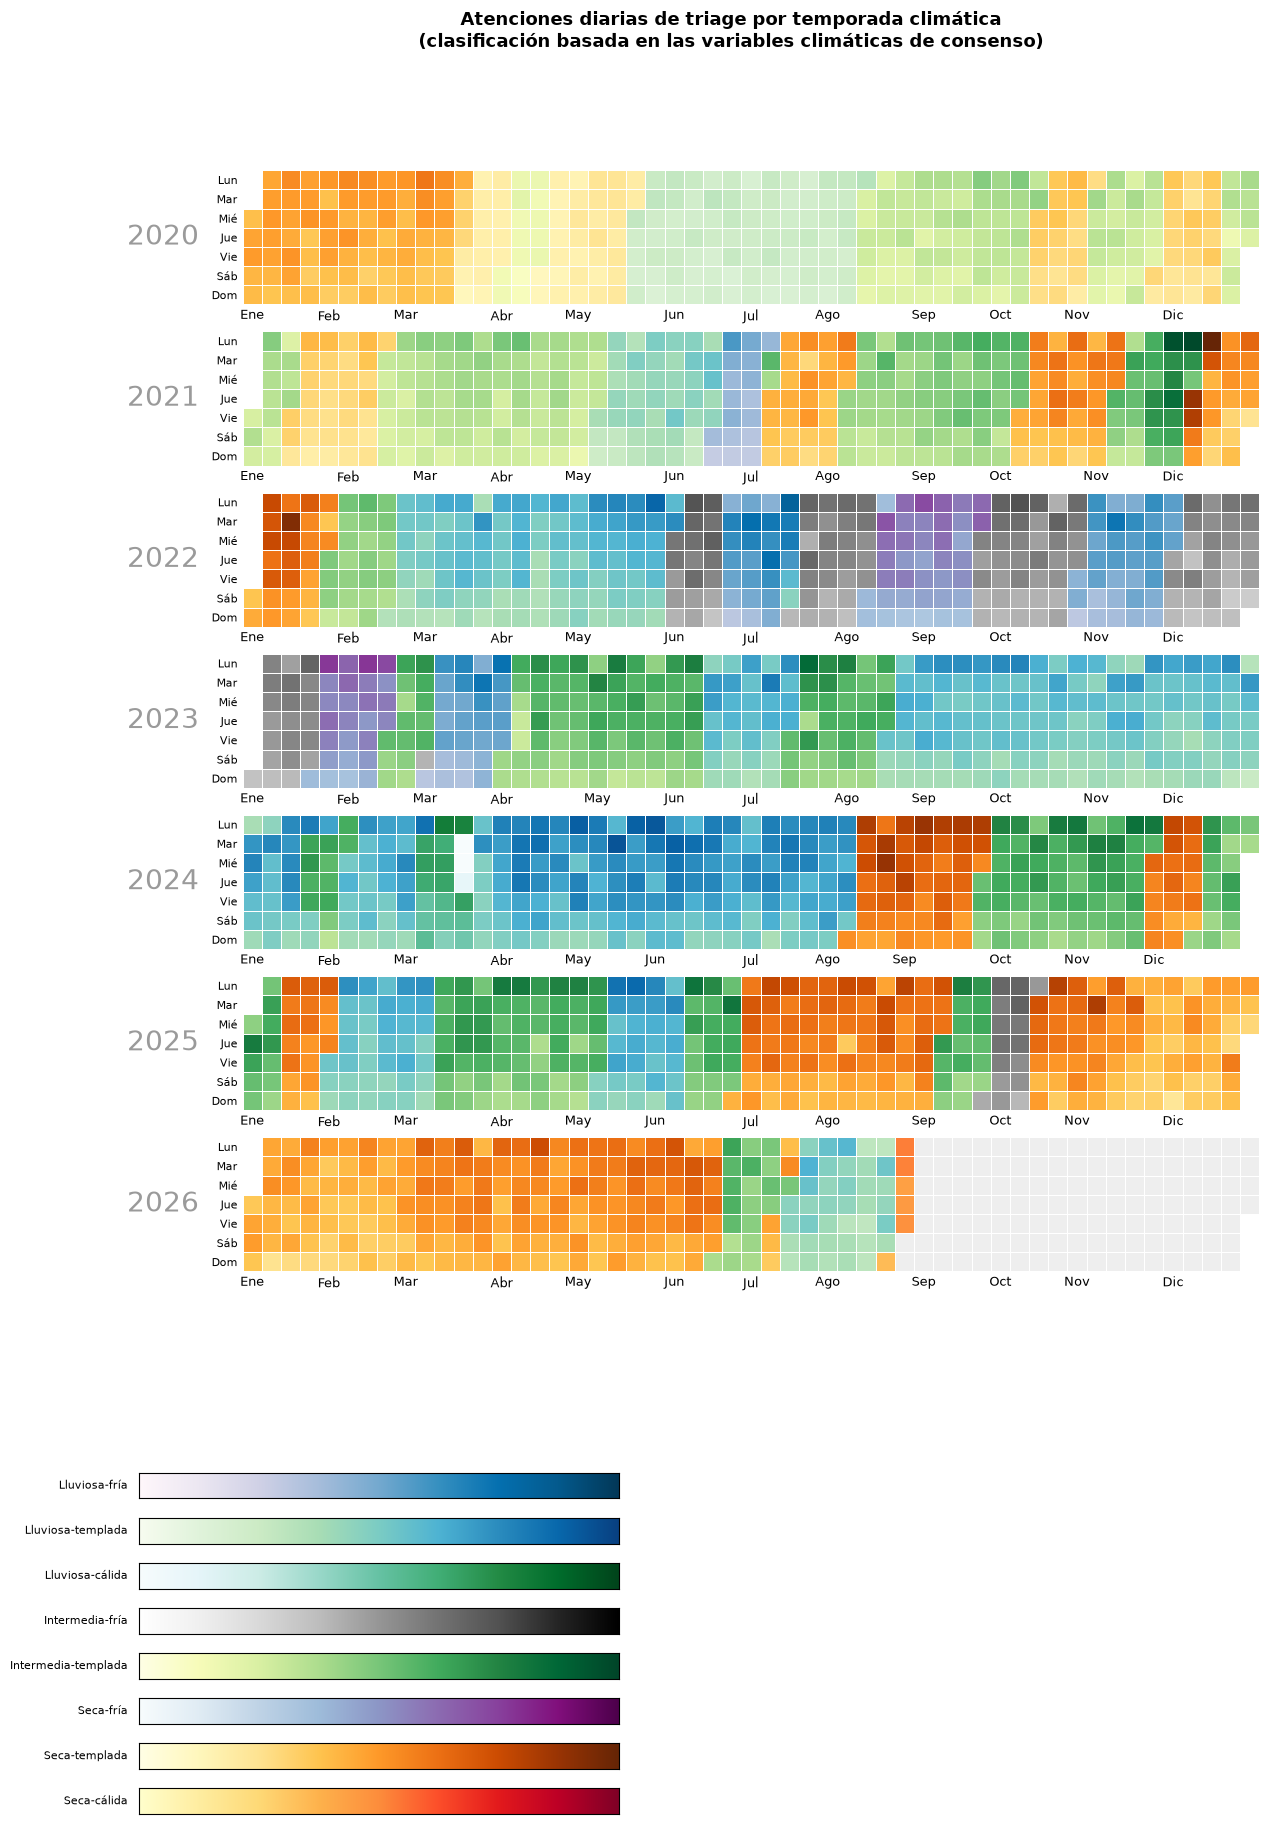

                     dias  triage_mediana  temp30_media  precip30_media
temporada                                                              
Lluviosa-cálida        20           201.0     17.565112      688.747000
Seca-fría              65           197.0     15.811015      157.972000
Intermedia-fría       152           191.0     15.694638      287.540559
Lluviosa-templada     694           189.0     16.677255      665.097233
Lluviosa-fría         103           186.0     15.852980      471.593932
Seca-cálida             6           170.5     17.842178      140.503333
Seca-templada         723           168.0     16.556248      154.314398
Intermedia-templada   669           165.0     16.483744      277.905740

Cortes de precipitación 30d — seco <= 217.6 mm | lluvioso >= 377.4 mm


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, ListedColormap

# ---------------- datos base ----------------
fecha = pd.to_datetime(df_triage_turnos["HCTFECTRI"], errors="coerce")
serie_triage = fecha.dropna().dt.normalize().value_counts().sort_index()

clima = df_clima.copy()
clima["fecha"] = pd.to_datetime(clima["fecha"], errors="coerce").dt.normalize()
clima = (clima.dropna(subset=["fecha"])
               .drop_duplicates("fecha")
               .set_index("fecha")
               .sort_index())

# El calendario climático conserva todas las fechas de la fuente.
# Los días sin triage se representan como cero, no como un espacio en blanco.
serie = serie_triage.reindex(clima.index, fill_value=0).astype(float)

print(f"Rango climático: {clima.index.min():%Y-%m-%d} -> {clima.index.max():%Y-%m-%d}")
print(f"Días con clima: {len(clima):,} | días con triage: {(serie > 0).sum():,} | días sin triage: {(serie == 0).sum():,}")

# ---------------- régimen climático (ventanas móviles) ----------------
# Las columnas de consenso mantienen cobertura cuando una fuente individual falla.
temp30 = clima["temp_media_consenso"].rolling(30, min_periods=10, center=True).mean()
precip30 = clima["precip_consenso_mm"].rolling(30, min_periods=10, center=True).sum()

UMBRAL_FRIO, UMBRAL_CALIDO = 16.0, 17.5
q_seco, q_lluvioso = precip30.quantile([0.33, 0.67])

def clasificar(t, p):
    if pd.isna(t) or pd.isna(p):
        return np.nan
    humedo = "Lluviosa" if p >= q_lluvioso else ("Seca" if p <= q_seco else "Intermedia")
    termico = "fría" if t < UMBRAL_FRIO else ("cálida" if t > UMBRAL_CALIDO else "templada")
    return f"{humedo}-{termico}"

cruda = pd.Series([clasificar(t, p) for t, p in zip(temp30, precip30)], index=clima.index)

def moda_ventana(s, idx, ventana=21):
    inicio = max(0, idx - ventana // 2)
    fin = min(len(s), idx + ventana // 2 + 1)
    bloque = s.iloc[inicio:fin].dropna()
    if bloque.empty:
        return np.nan
    return bloque.mode().iloc[0]

temporada = pd.Series(
    [moda_ventana(cruda, i) for i in range(len(cruda))],
    index=cruda.index,
    dtype="object",
)

CMAPS = {
    "Lluviosa-fría": "PuBu",
    "Lluviosa-templada": "GnBu",
    "Lluviosa-cálida": "BuGn",
    "Intermedia-fría": "Greys",
    "Intermedia-templada": "YlGn",
    "Intermedia-cálida": "YlGnBu",
    "Seca-fría": "BuPu",
    "Seca-templada": "YlOrBr",
    "Seca-cálida": "YlOrRd",
}
presentes = [etq for etq in CMAPS if (temporada == etq).any()]

norm = Normalize(serie.min(), serie.max() if serie.max() > serie.min() else serie.min() + 1)
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

# ---------------- calendario por temporada climática ----------------
anios = sorted(clima.index.year.unique())
fig, axes = plt.subplots(len(anios), 1, figsize=(16, 2.3 * len(anios)), squeeze=False)

for ax, anio in zip(axes[:, 0], anios):
    idx = pd.date_range(f"{anio}-01-01", f"{anio}-12-31", freq="D")
    val = serie.reindex(idx, fill_value=0).to_numpy(dtype=float)
    temp = temporada.reindex(idx).to_numpy(dtype=object)

    offset = pd.Timestamp(f"{anio}-01-01").dayofweek
    semana = ((idx.dayofyear.to_numpy() - 1 + offset) // 7).astype(int)
    dia = idx.dayofweek.to_numpy(dtype=int)
    nsem = int(semana.max()) + 1
    kw = dict(edgecolors="white", linewidth=0.5)

    fondo = np.full((7, nsem), np.nan)
    fondo[dia, semana] = 1.0
    ax.pcolormesh(np.ma.masked_invalid(fondo), cmap=ListedColormap(["#eeeeee"]), **kw)

    for etq in presentes:
        sel = np.isfinite(val) & (temp == etq)
        if not sel.any():
            continue
        capa = np.full((7, nsem), np.nan)
        capa[dia[sel], semana[sel]] = val[sel]
        ax.pcolormesh(np.ma.masked_invalid(capa), cmap=CMAPS[etq], norm=norm, **kw)

    pos_mes = [semana[idx.month == mth][0] + 0.5 for mth in range(1, 13)]
    ax.set_xticks(pos_mes, MESES, fontsize=9)
    ax.set_yticks(np.arange(7) + 0.5, DIAS, fontsize=8)
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.set_frame_on(False)
    ax.tick_params(length=0)
    ax.set_ylabel(anio, fontsize=20, color="#9a9a9a", rotation=0, labelpad=35, va="center")

fig.suptitle(
    "Atenciones diarias de triage por temporada climática\n"
    "(clasificación basada en las variables climáticas de consenso)",
    fontsize=13,
    weight="bold",
)

grad = np.linspace(0, 1, 256).reshape(1, -1)
fig.subplots_adjust(bottom=0.10 + 0.012 * len(presentes))
for k, etq in enumerate(presentes):
    cax = fig.add_axes([0.13, 0.055 - 0.028 * k, 0.30, 0.016])
    cax.imshow(grad, aspect="auto", cmap=CMAPS[etq])
    cax.set_xticks([])
    cax.set_yticks([])
    cax.set_ylabel(etq, rotation=0, ha="right", va="center", fontsize=8, labelpad=8)
plt.show()

# ---------------- resumen de la segmentación ----------------
resumen = (
    pd.DataFrame({"triage": serie, "temporada": temporada, "temp30": temp30, "precip30": precip30})
    .dropna(subset=["temporada"])
    .groupby("temporada")
    .agg(
        dias=("temporada", "size"),
        triage_mediana=("triage", "median"),
        temp30_media=("temp30", "mean"),
        precip30_media=("precip30", "mean"),
    )
    .sort_values("triage_mediana", ascending=False)
)
print(resumen)
print("\nCortes de precipitación 30d — seco <= %.1f mm | lluvioso >= %.1f mm" % (q_seco, q_lluvioso))

No se puede determinar una relacion directa entre el clima y las tendencias de registros en los triages debido a que no se tiene mas informacion de la cual se pueda sabe rla causa de consulta, por lo cual se realizará una exploracion mas amplia de la base de datos para obtener mas inforamcion de la causa de la consulta y encontrar una correlacion veridica sobre el triage y factores exrternos.

In [ ]:

query = """
SELECT TOP 20
    c.OID,
    c.HCTFECTRI,
    c.HCNCLAURGTR,
    c.HCNCONTRDT,
    c.HCTMOTCON
FROM DIM_TRIAGE c
WHERE CAST(c.HCTFECTRI AS DATE) = '2025-02-01'
ORDER BY c.OID
"""

df = pd.read_sql(query, engine)

print(df.to_string(index=False))


   OID               HCTFECTRI  HCNCLAURGTR  HCNCONTRDT                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   HCTMOTCON
726382 2025-02-01 00:30:51.290           19    716402.0                                                                                                                                                                                                                                                                                                                                                                                                             

: 

In [ ]:
query = """
SELECT TOP 20
    *
FROM DIM_HCNCONTRDT c
ORDER BY c.OID
"""

df = pd.read_sql(query, engine)

print(df.to_string(index=False))


   OID  HCNCONCOTRI               HCCFECTUR               HCCFECSAL  HCCESTADO  HCLLTIPO  GENUSUARIO HCCTTURNO
100038            5 2020-01-01 00:05:44.020 2020-01-01 00:24:38.520          1         0        2101      None
100039            5 2020-01-01 00:17:41.853 2020-01-01 00:24:43.377          1         0        2101      None
100040            1 2020-01-01 00:18:18.480 2020-01-01 00:27:17.090          1         0        2101      None
100041            1 2020-01-01 00:30:41.563 2020-01-01 00:32:19.813          1         0        2101      None
100042            1 2020-01-01 00:39:57.680 2020-01-01 00:42:17.017          1         0        2101      None
100043            4 2020-01-01 01:01:43.407 2020-01-01 01:02:59.103          1         0        2101      None
100044            1 2020-01-01 01:40:56.807 2020-01-01 01:44:24.003          1         0        2101      None
100045            1 2020-01-01 02:12:15.440 2020-01-01 02:15:34.363          1         0        2101      None
1

In [ ]:
query = """
SELECT TOP 20
    c.OID,
    c.HCCODIGO,
    c.HCDESCRIP,
    c.HCPRIORIDAD,
    c.HCAREA
FROM HCNCONCOTRI_DW c
ORDER BY c.OID
"""

df = pd.read_sql(query, engine)

print(df.to_string(index=False))


 OID  HCCODIGO                                                                HCDESCRIP  HCPRIORIDAD  HCAREA
   1         1                                                                   TRIAGE            4       1
   2         2                                                      TRIAGE PREFERENCIAL            2       1
   3         3                                                              TRIAGE SOAT            3       1
   4         4 TRIAGE ADULTO MAYOR/RECIEN NACIDOS/DISCAPACITADOS/CARCELARIOS/ALTO COSTO            1       1
   5         5                                                        TRIAGE OBSTETRICO            4       1
   6         6                                           TRIAGE PREFERENCIAL OBSTETRICO            2       1
   7         7                                                      TRIAGE RESPIRATORIO            1       1
   8         8                                                     LABORATORIO EFECTIVO            1      26
   9         9     

In [ ]:
sql = """
SELECT
    c.*,
    COUNT(*) AS CANTIDAD
FROM DIM_TRIAGE t
INNER JOIN DIM_HCNCLAURGTR c
    ON t.HCNCLAURGTR = c.OID
GROUP BY
    c.OID,
    c.HCCODIGO,
    c.HCDESCRIP
ORDER BY CANTIDAD DESC
"""

df = pd.read_sql(sql, engine)

print(df.to_string(index=False))

 OID HCCODIGO                            HCDESCRIP  CANTIDAD
  10       IV                  DIFERIDA/NO URGENTE    168730
  16     IIIU                             URGENCIA    105886
  12        V                     CONSULTA EXTERNA     52695
  19    III-G URGENCIA OBSTETRICA DIFERIDA O MENOR     46830
   9      III                             DIFERIDA     40514
   2       II                      URGENCIA MEDICA      6422
  18     II-G           URGENCIA MEDICA OBSTETRICA      6221
   7        I                           EMERGENCIA      1411
  14        M                               MUERTO       285
  20     IV-G                NO URGENTE OBSTETRICA       264
  17      I-G                EMERGENCIA OBSTETRICA       131
  11       UA                     PACIENTE AUSENTE        61
  21      V-G          CONSULTA EXTERNA OBSTETRICA        59
  13      IIP   NO USAR URGENCIA MEDICA PRIORIZADA        30
  15      IIS         NO USAR URGENCIA MEDICA SOAT        29


Revisando la base de datos se puede encontrar 3 tablas adcionales las cuales muestran mas informacion sobre que paso con el triage.

Ramificaciones de la tabla triage que pueden ofrecer un mejor panorama sobre la gestion relizada sore este triage:
DIM TRIAGE =>  Nos ofrece una informacion detalada de lo sucedido e la consulta ahora con una nueva columna con el comentario gneerado al momento de generar el registro del triage
DIM_HCNCLAURGTR => Encontramos una clasificacion de gravedad del triage, pasa saber cual fue el siguiente paso a realizar con este usuario
DIM_HCNCONTRDT=> Informacion hisitrica de fechas y horas tanto de ingreso como de salida del triage ademas de conexiones con otras tablas que ofrecen mas informacion como HCNCONCOTRI_DW
HCNCONCOTRI_DW => Informacion sobre el tipo de triage realizado y el area encargada de realizarlo

se procede a realizar una conexion entre todas las tablas encontradas para generar yna unica fuente de verdad para extraer datos informativos sobre el moitivo el triage y su conexion con datos externos calendario.


Para esto se ha generado un archivo el cual se encarga de generar un poceso de mineria de texto el cula servira para, limpiar, normalizar y analizar las notas medicas del motivo de consulta representadas en al columna de HCTMOTCON de la tabla traige, ya que con base a esta fuente de iformacion nos será posible obter la cuasa del triage y poder enfrentarlo contra los factoes externos ya obtenidos.

In [17]:
# Archivo de motivo de triaje limpio, normalizado y estandarizado

df_motivo_triage = pd.read_csv(r"NLP\triage_limpio.csv")
print(df_motivo_triage)


          OID                                     texto_original  \
0      769938  "DESDE ESTA MADRUGADA ESTA CON FLEMA Y NO LO D...   
1      756613                                Tengo mucho cólico    
2      840203  PRIMIGESTANTE DE 19.6SMS CONSULTA POR 4 DIAS D...   
3      735715                             TENGO DOLOR ABDOMINAL    
4      782655                               MC:" LA REMITIERON"    
...       ...                                                ...   
29995  798233                     ESTA CON SANGRADO POR LA NARIZ   
29996  753279                                    ESTA MUY MALUCO   
29997  836161  INGRESA PACIENTE EN SILLA DE RUEDAS CON ACOMPA...   
29998  834175                 PACIENTE REFIERE SE CORTO UN DEDO    
29999  820559                          AP: PARKINSON\nAA: NIEGA    

                                         texto_corregido  \
0      desde esta madrugada esta con flema y no lo de...   
1                                     tengo mucho cólico   
2  

Se han utilizado tecnicas de mineria de texto para limpiar los textos de las notas clinicas, pasa pasar de una nota confusa, con mala ortografia y sin una estructura clara a generar ubn proceso de correccion general del texto para que sea mas legible y una estructuracion y despgloce de la nota para identificar cada una de las partes importantes de la nota, obvianto informacion poco utilpar ael analisis, resultado en un desglose del texto, entenindmiento y clasificacion de sintomatologias, y gneeracion de texto limpio para ser usado en modelos de embedding enfocados en textos e informacion compleja y clinica

In [ ]:
# visualizacion de estructura final



Luego de concluir con la estructracion y desglose correcto de la estructra de la nota medica del triage, se procede a usar la estructura correcta y personalizada para el modelo de embedding que se va a urulizar, la finalidad de esto es poder tener un mejor reconocimienoto de los cocenos cercanos para obtener clustering mucho mas enfocado en verdaderos conjuntos de sintomas o motivos de registor de triage.

La finalidad de esto es poder entender los gurpos de motivos por los cuales usuarios se acercan al hospital y poder enfrentarlo contra las fechas historicas con la finalidad de encontrar patrones entre los grupos de clustering y los dias o temporadas en las uqe los regstros de trage han aumentado 

In [18]:
import pandas as pd
import numpy as np
import torch

from sentence_transformers import SentenceTransformer

# =====================================================
# CARGA
# =====================================================

# Usar el DataFrame ya cargado en la celda anterior
df = df_motivo_triage.copy()

TEXT_COLUMN = "texto_normalizado"


df = df.dropna(subset=[TEXT_COLUMN]).copy()

# ====================================
# MUESTRA ALEATORIA PARA PRUEBAS
# ====================================

N_MUESTRA = 5000

if len(df) > N_MUESTRA:
    df = (
        df.sample(
            n=N_MUESTRA,
            random_state=42
        )
        .reset_index(drop=True)
    )

print(f"Registros para la prueba: {len(df):,}")

# =====================================================
# MODELO
# =====================================================

if tuple(map(int, torch.__version__.split(".")[:2])) < (2, 6):
    raise RuntimeError(
        f"Torch {torch.__version__} no es compatible. "
        "Instala torch==2.6.0 o una version posterior y reinicia el kernel."
    )

model = SentenceTransformer(
    "BAAI/bge-m3"
)

# =====================================================
# EMBEDDINGS
# =====================================================

embeddings = model.encode(
    df[TEXT_COLUMN].tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Embeddings generados")

# =====================================================
# GUARDAR EMBEDDINGS
# =====================================================

df["embedding"] = embeddings.tolist()

df.to_parquet(
    "triage_embedding_bge_m3.parquet",
    index=False
)

print("Parquet guardado")

Registros para la prueba: 5,000


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Embeddings generados
Parquet guardado


In [19]:
import pandas as pd
import numpy as np

df = pd.read_parquet(
    "triage_embedding_bge_m3.parquet"
)

embeddings = np.vstack(
    df["embedding"].values
)

print(embeddings.shape)

(5000, 1024)


In [20]:
import umap

umap_model = umap.UMAP(
    n_neighbors=30,
    min_dist=0.0,
    n_components=50,
    metric="cosine",
    random_state=42
)

embeddings_umap = umap_model.fit_transform(
    embeddings
)

print(embeddings_umap.shape)

c:\Users\ad6708\Documents\puebas\.venv311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(5000, 50)


In [23]:
import hdbscan

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=20,
    min_samples=20,
    metric="euclidean"
)

clusters = clusterer.fit_predict(
    embeddings_umap
)

df["cluster"] = clusters

print(
    df["cluster"]
    .value_counts()
    .sort_index()
)

df.to_parquet(
    "triage_clusterizado.parquet",
    index=False
)

print("Clusterización guardada")

cluster
-1     1022
 0      110
 1       44
 2       49
 3       36
       ... 
 55      27
 56      51
 57      20
 58      20
 59      37
Name: count, Length: 61, dtype: int64
Clusterización guardada


In [24]:
import umap
import plotly.express as px

umap_vis = umap.UMAP(
    n_neighbors=30,
    min_dist=0.05,
    n_components=2,
    metric="cosine",
    random_state=42
)

vis = umap_vis.fit_transform(
    embeddings
)

plot_df = pd.DataFrame({
    "x": vis[:, 0],
    "y": vis[:, 1],
    "cluster": df["cluster"].astype(str),
    "texto": df["texto_normalizado"]
})

fig = px.scatter(
    plot_df,
    x="x",
    y="y",
    color="cluster",
    hover_data=["texto"],
    title="Clusters de Triages"
)

fig.update_layout(
    height=900,
    width=1500
)

fig.show()

c:\Users\ad6708\Documents\puebas\.venv311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [25]:
TEXT_COLUMN = "texto_normalizado"

# Recuperar las etiquetas si el kernel fue reiniciado o las celdas se ejecutaron fuera de orden.
if "cluster" not in df.columns:
    if "clusters" in globals() and len(clusters) == len(df):
        df["cluster"] = clusters
    else:
        ruta_clusterizado = "triage_clusterizado.parquet"
        df_clusterizado = pd.read_parquet(ruta_clusterizado)
        if "cluster" not in df_clusterizado.columns:
            raise KeyError(
                f"{ruta_clusterizado} no contiene la columna 'cluster'. "
                f"Columnas disponibles: {list(df_clusterizado.columns)}"
            )
        if len(df_clusterizado) != len(df):
            raise ValueError(
                "El archivo clusterizado no tiene la misma cantidad de filas que df. "
                f"df={len(df)}, archivo={len(df_clusterizado)}"
            )
        df["cluster"] = df_clusterizado["cluster"].to_numpy()

for c in sorted(df["cluster"].unique()):

    if c == -1:
        continue

    subset = df[df["cluster"] == c]

    print(
        f"\nCLUSTER {c}"
    )

    print(
        f"Casos: {len(subset):,}"
    )

    muestras = subset[
        TEXT_COLUMN
    ].sample(
        min(10, len(subset)),
        random_state=42
    )

    for t in muestras:
        print("-", t)


CLUSTER 0
Casos: 110
- ap (antecedentes personales): niega; aa (antecedentes alérgicos): niega; motivo de consulta por mi ojito
- ap (antecedentes personales): barro biliar ansiedad; aa (antecedentes alérgicos): niega
- ap (antecedentes personales): niega; aa (antecedentes alérgicos): niega
- ap (antecedentes personales): niega; aa (antecedentes alérgicos): niega
- ap (antecedentes personales): niega; aa (antecedentes alérgicos): niega
- ap (antecedentes personales): niega; aa (antecedentes alérgicos): niega
- ap (antecedentes personales): niega; aa (antecedentes alérgicos): niega
- ap (antecedentes personales): niega; aa (antecedentes alérgicos): niega
- ap (antecedentes personales): niega; aa (antecedentes alérgicos): niega; motivo de consulta se cayo (caída) jugando futbol
- ap (antecedentes personales): niega; aa (antecedentes alérgicos): niega; motivo de consulta me esta doliendo esta aprte

CLUSTER 1
Casos: 44
- me caí
- me caí
- me caí
- me caí
- me caí
- me caí
- me caí
- me c